In [1]:
import pandas as pd
from pathlib import Path

train_path = Path("../data/splits_60_20_20/train.csv")

# Load only the columns we need
train_df = pd.read_csv(
    train_path,
    usecols=["user_id", "gmap_id"],
    dtype={"user_id": "string", "gmap_id": "string"}
)

# Count distinct users per activity
activity_popularity = (
    train_df.groupby("gmap_id")["user_id"]
    .nunique()
    .reset_index(name="popularity_count")
)

print(activity_popularity.shape)
display(activity_popularity.head())

(69783, 2)


,gmap_id,popularity_count
0,0x40543aeb3f93f6cb:0xd0e406400bfd4d45,66
1,0x4056c170f484c405:0x6b0f002e2cc683b8,102
2,0x405a2ffe3f2ec327:0xa873a8b093605aa3,17
3,0x405a318a8da05f89:0x7d838984839ee297,168
4,0x405a31c1794e4035:0x777fb0ec24ab6d41,121


In [2]:
output_path = Path("../data/processed/activity_popularity.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

activity_popularity.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: ../data/processed/activity_popularity.csv



# Popularity-Aware Reranking

## 1. Activity Popularity Classification

This notebook develops a user-specific popularity-aware reranking component for the Activity Recommendation System.

The objective is to account for individual preferences toward popular and less-popular activities while preserving relevance from the original Bayesian Personalized Ranking (BPR) model.

Activity popularity is measured by the number of distinct users with positive training interactions. Activities are classified into three popularity groups:

- **Long-tail:** Activities in the bottom 50% of the popularity distribution.
- **Mid-tail:** Activities between the 50th and 90th percentiles.
- **Popular (head):** Activities above the 90th percentile.

These thresholds provide an initial classification for subsequent personalization and evaluation.


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Update this path if your notebook is in a different folder.
popularity_path = Path("../data/processed/activity_popularity.csv")

activity_popularity = pd.read_csv(
    popularity_path,
    dtype={"gmap_id": "string"}
)

print("Dataset shape:", activity_popularity.shape)
print("\nMissing values:")
print(activity_popularity.isna().sum())

display(activity_popularity.head())


Dataset shape: (69783, 2)

Missing values:
gmap_id             0
popularity_count    0
dtype: int64


,gmap_id,popularity_count
0,0x40543aeb3f93f6cb:0xd0e406400bfd4d45,66
1,0x4056c170f484c405:0x6b0f002e2cc683b8,102
2,0x405a2ffe3f2ec327:0xa873a8b093605aa3,17
3,0x405a318a8da05f89:0x7d838984839ee297,168
4,0x405a31c1794e4035:0x777fb0ec24ab6d41,121



### 1.1 Popularity Distribution

Before assigning popularity groups, we examine the distribution of distinct-user interaction counts.

This analysis helps determine whether popularity is evenly distributed across activities or concentrated among a smaller number of highly interacted-with locations.

Percentile-based thresholds are used because the popularity distribution is highly skewed.


In [4]:

# Calculate popularity percentile thresholds
p50 = activity_popularity["popularity_count"].quantile(0.50)
p90 = activity_popularity["popularity_count"].quantile(0.90)

print(f"50th percentile: {p50:.2f}")
print(f"90th percentile: {p90:.2f}")

# Classify activities into popularity groups
activity_popularity["popularity_group"] = np.select(
    [
        activity_popularity["popularity_count"] <= p50,
        activity_popularity["popularity_count"] <= p90
    ],
    [
        "Long-tail",
        "Mid-tail"
    ],
    default="Popular"
)

print("\nPopularity group counts:")
print(activity_popularity["popularity_group"].value_counts())

display(activity_popularity.head(10))


50th percentile: 37.00
90th percentile: 213.80

Popularity group counts:
popularity_group
Long-tail    34986
Mid-tail     27818
Popular       6979
Name: count, dtype: int64


,gmap_id,popularity_count,popularity_group
0,0x40543aeb3f93f6cb:0xd0e406400bfd4d45,66,Mid-tail
1,0x4056c170f484c405:0x6b0f002e2cc683b8,102,Mid-tail
2,0x405a2ffe3f2ec327:0xa873a8b093605aa3,17,Long-tail
3,0x405a318a8da05f89:0x7d838984839ee297,168,Mid-tail
4,0x405a31c1794e4035:0x777fb0ec24ab6d41,121,Mid-tail
5,0x405a31cd677e0c05:0x80e20fc2bd8da2fd,304,Popular
6,0x405a3247c8befd13:0x1a5679dff46154a6,101,Mid-tail
7,0x405a331fe4eaaaa1:0x455aa8cd1ca1cd94,32,Long-tail
8,0x405b8a1c944dca2d:0x9401d4215cde1641,47,Mid-tail
9,0x405b8bc6663ebeed:0x5bf925a933c1ad12,35,Long-tail



### 1.2 Visualization of Activity Popularity

The following line graph illustrates the distribution of activity popularity across percentiles.

The horizontal axis represents the popularity percentile, while the vertical axis shows the number of distinct users who interacted with an activity.

The 50th and 90th percentile thresholds indicate the boundaries used to classify long-tail, mid-tail, and popular activities.

This visualization helps illustrate the concentration of interactions among highly popular activities.


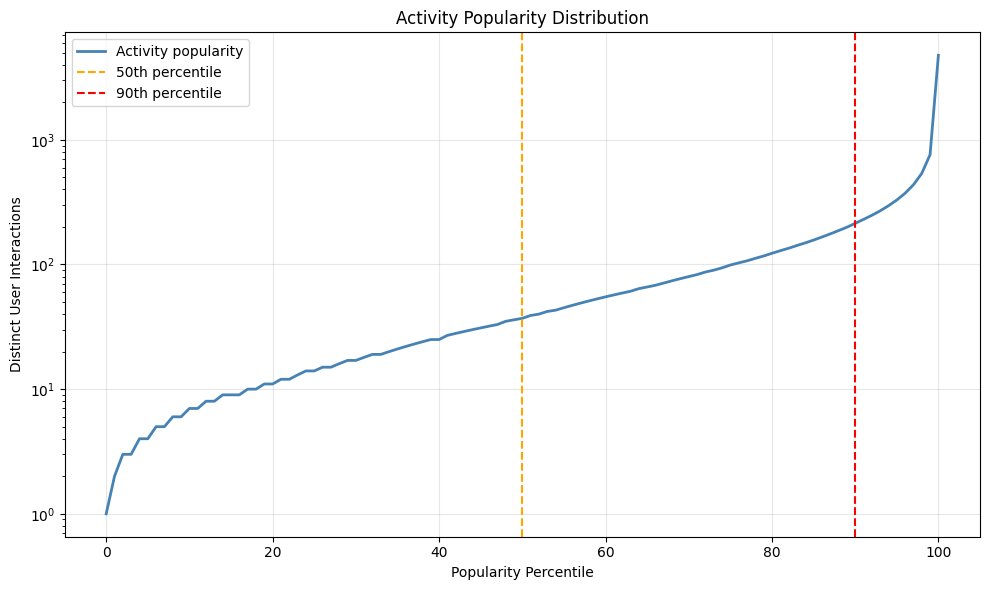

In [6]:

# Calculate popularity across percentiles
percentiles = np.arange(0, 101)

popularity_values = np.percentile(
    activity_popularity["popularity_count"],
    percentiles
)

plt.figure(figsize=(10, 6))

plt.plot(
    percentiles,
    popularity_values,
    linewidth=2,
    color="steelblue",
    label="Activity popularity"
)

plt.axvline(
    50,
    color="orange",
    linestyle="--",
    label="50th percentile"
)

plt.axvline(
    90,
    color="red",
    linestyle="--",
    label="90th percentile"
)

plt.xlabel("Popularity Percentile")
plt.ylabel("Distinct User Interactions")
plt.title("Activity Popularity Distribution")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 1.3 Popularity Group Visualization

Activities are visualized according to their popularity ranking and number of distinct-user interactions.

Each point represents an activity, and its color indicates whether it belongs to the long-tail, mid-tail, or popular group.

This visualization allows us to inspect the separation between popularity groups and identify highly popular activities.


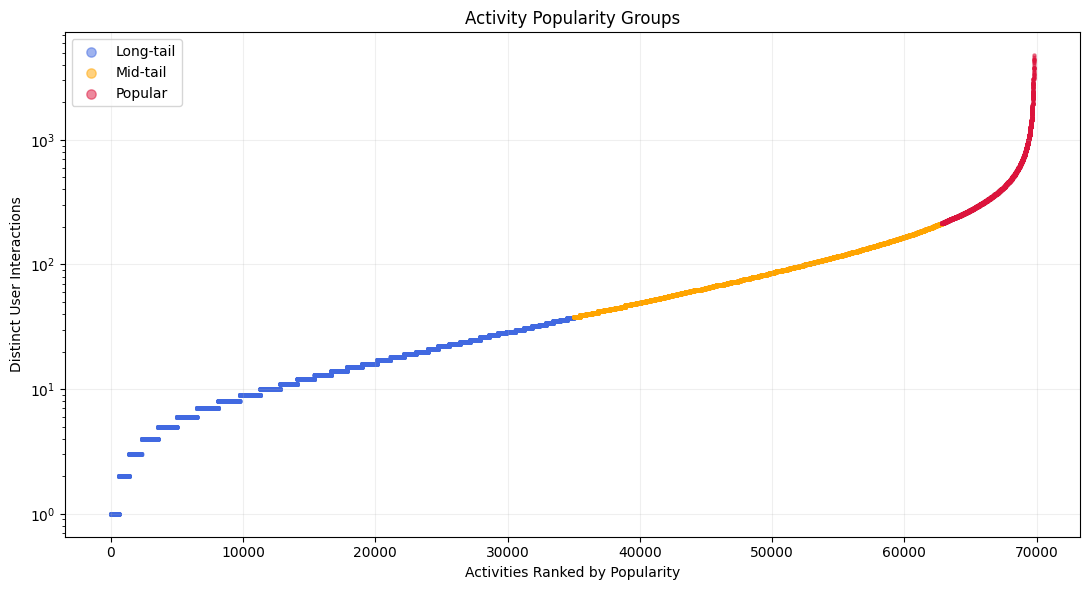

In [7]:

# Sort activities from least to most popular
plot_df = activity_popularity.sort_values(
    "popularity_count"
).reset_index(drop=True)

plot_df["activity_rank"] = np.arange(1, len(plot_df) + 1)

colors = {
    "Long-tail": "royalblue",
    "Mid-tail": "orange",
    "Popular": "crimson"
}

plt.figure(figsize=(11, 6))

for group, color in colors.items():
    subset = plot_df[
        plot_df["popularity_group"] == group
    ]

    plt.scatter(
        subset["activity_rank"],
        subset["popularity_count"],
        s=5,
        alpha=0.5,
        color=color,
        label=group
    )

plt.xlabel("Activities Ranked by Popularity")
plt.ylabel("Distinct User Interactions")
plt.title("Activity Popularity Groups")
plt.yscale("log")
plt.legend(markerscale=3)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### 1.4 Saving Activity Popularity Groups

The classified activity dataset is saved for use in the subsequent user-specific popularity calibration stage.

Each activity is associated with its distinct-user interaction count and assigned popularity group.

These classifications will be joined with historical user interactions to estimate each user's preference for popular, mid-tail, and long-tail activities.


In [8]:

output_path = Path(
    "../data/processed/activity_popularity_groups.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

activity_popularity.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

print("\nFinal dataset shape:")
print(activity_popularity.shape)

print("\nPopularity group distribution:")
print(
    activity_popularity["popularity_group"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Saved: ../data/processed/activity_popularity_groups.csv

Final dataset shape:
(69783, 3)

Popularity group distribution:
popularity_group
Long-tail    50.14
Mid-tail     39.86
Popular      10.00
Name: proportion, dtype: float64



### 1.5 Results and Interpretation

A total of 69,783 activities were classified into three popularity groups using distinct-user interaction counts from the training data.

The classification resulted in 50.14% long-tail activities, 39.86% mid-tail activities, and 10.00% popular activities.

The popularity distribution exhibits a pronounced upper tail, with a relatively small proportion of activities receiving substantially more interactions than others.

These results establish the popularity categories needed for user-specific popularity calibration. However, activity-level popularity alone does not reveal whether individual users prefer mainstream or niche activities. This requires analyzing each user's historical interactions.



## 2. User-Specific Popularity Profiles

Activity popularity classification identifies the relative popularity of each activity. However, users may differ in their historical interactions with popular and less-popular activities.

To capture these differences, we construct user-specific popularity profiles using the training interaction dataset.

For each user, we calculate the proportion of distinct interacted activities belonging to three groups:

- Long-tail activities
- Mid-tail activities
- Popular activities

These profiles represent observed historical popularity tendencies and will be used to guide personalized popularity-aware reranking.


In [9]:

# Load historical user-activity interactions
train_path = Path("../data/splits_60_20_20/train.csv")

train_df = pd.read_csv(
    train_path,
    usecols=["user_id", "gmap_id"],
    dtype={
        "user_id": "string",
        "gmap_id": "string"
    }
)

print("Total training interactions:", len(train_df))
print("Unique users:", train_df["user_id"].nunique())
print("Unique activities:", train_df["gmap_id"].nunique())

display(train_df.head())


Total training interactions: 6303944
Unique users: 627365
Unique activities: 69783


,user_id,gmap_id
0,100000012795753291799,0x89c25d977025692d:0x378d24e13eb8f34d
1,100000012795753291799,0x89c258e28c304997:0xfcafe4e7ce35ee8c
2,100000012795753291799,0x89c2590f34e21a53:0x749079380908a830
3,100000012795753291799,0x89c25999b9c6eff9:0x4b98becb736928d8
4,100000012795753291799,0x89c25cfd883fc003:0xb4ba2be70609711b


In [10]:

# Keep one interaction per user-activity pair
unique_interactions = train_df[
    ["user_id", "gmap_id"]
].drop_duplicates()

# Join training interactions with activity popularity groups
user_activity_groups = unique_interactions.merge(
    activity_popularity[
        ["gmap_id", "popularity_group"]
    ],
    on="gmap_id",
    how="left",
    validate="many_to_one"
)

print("Unique user-activity interactions:", len(user_activity_groups))

missing_groups = (
    user_activity_groups["popularity_group"].isna().sum()
)

print("Missing popularity classifications:", missing_groups)

display(user_activity_groups.head())

assert missing_groups == 0, "Some activities have no popularity group."


Unique user-activity interactions: 6303944
Missing popularity classifications: 0


,user_id,gmap_id,popularity_group
0,100000012795753291799,0x89c25d977025692d:0x378d24e13eb8f34d,Popular
1,100000012795753291799,0x89c258e28c304997:0xfcafe4e7ce35ee8c,Mid-tail
2,100000012795753291799,0x89c2590f34e21a53:0x749079380908a830,Popular
3,100000012795753291799,0x89c25999b9c6eff9:0x4b98becb736928d8,Popular
4,100000012795753291799,0x89c25cfd883fc003:0xb4ba2be70609711b,Popular



### 2.1 Calculating Historical Popularity Preferences

A user's historical popularity profile is calculated by dividing the number of distinct activities they interacted with in each popularity group by their total number of distinct interacted activities.

Each profile contains three proportions that sum to 1.

These proportions describe the user's observed interaction patterns rather than explicitly stated preferences.

The resulting profiles provide a personalized target distribution for subsequent popularity-aware reranking.


In [11]:

# Count distinct interacted activities per popularity group
user_group_counts = (
    user_activity_groups
    .groupby(["user_id", "popularity_group"])
    .size()
    .unstack(fill_value=0)
)

groups = ["Long-tail", "Mid-tail", "Popular"]

user_group_counts = user_group_counts.reindex(
    columns=groups,
    fill_value=0
)

# Convert interaction counts into proportions
user_popularity_profiles = user_group_counts.div(
    user_group_counts.sum(axis=1),
    axis=0
)

user_popularity_profiles.columns = [
    "long_tail_preference",
    "mid_tail_preference",
    "popular_preference"
]

user_popularity_profiles = (
    user_popularity_profiles.reset_index()
)

print("User popularity profiles shape:")
print(user_popularity_profiles.shape)

display(user_popularity_profiles.head())

# Check that proportions sum to 1
profile_cols = [
    "long_tail_preference",
    "mid_tail_preference",
    "popular_preference"
]

assert np.allclose(
    user_popularity_profiles[profile_cols].sum(axis=1),
    1.0
)

print("All user profiles sum to 1.")


User popularity profiles shape:
(627365, 4)


,user_id,long_tail_preference,mid_tail_preference,popular_preference
0,100000012795753291799,0.0,0.200000,0.800000
1,100000036464530353686,0.1,0.333333,0.566667
2,100000078039055967014,0.1,0.300000,0.600000
3,100000107216850094011,0.0,0.500000,0.500000
4,100000112816996363851,0.0,0.166667,0.833333


All user profiles sum to 1.



### 2.2 Results and Interpretation

The training dataset contains 6,303,944 user-activity interactions involving 627,365 unique users and 69,783 activities.

All interactions were successfully matched to an activity popularity group, with no missing classifications.

User-specific popularity profiles were calculated as the proportion of historical interactions associated with long-tail, mid-tail, and popular activities. All profiles were verified to sum to 1.

The initial results demonstrate differences in observed popularity tendencies across users. These profiles will provide personalized target distributions for the popularity-aware reranking component.

However, historical interaction distributions may also reflect differences in activity exposure and interaction history length.



### 2.3 Visualization of User Popularity Profiles

A ternary scatter plot is used to visualize differences in historical popularity tendencies across users.

Each point represents a user, positioned according to their proportions of long-tail, mid-tail, and popular activity interactions.

The three vertices represent users whose interactions fall entirely within one popularity group, while points in the interior represent mixed interaction histories.

This visualization helps assess whether users exhibit varied popularity tendencies and motivates user-specific rather than uniform popularity calibration.


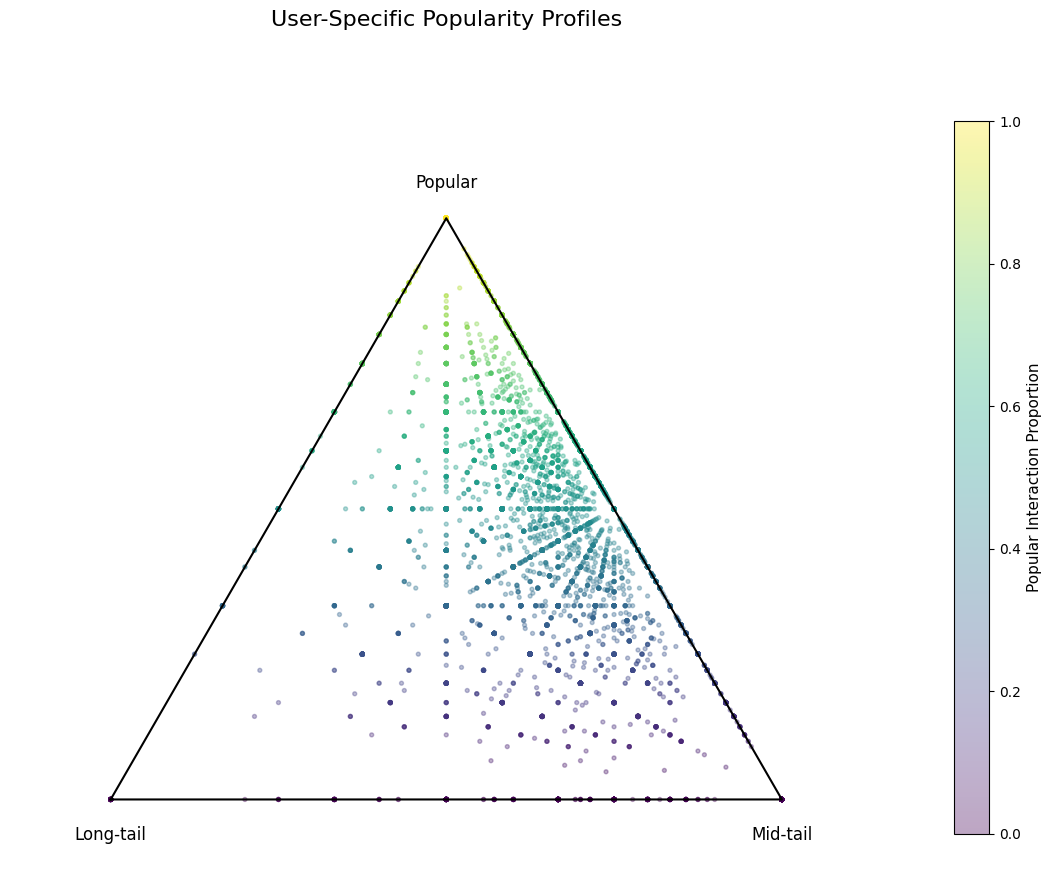

In [15]:

# Sample users for clearer visualization
plot_profiles = user_popularity_profiles.sample(
    n=min(10000, len(user_popularity_profiles)),
    random_state=42
).copy()

# Extract popularity proportions
L = plot_profiles["long_tail_preference"].to_numpy()
M = plot_profiles["mid_tail_preference"].to_numpy()
P = plot_profiles["popular_preference"].to_numpy()

# Convert ternary coordinates to 2D
x = M + 0.5 * P
y = (np.sqrt(3) / 2) * P

fig, ax = plt.subplots(figsize=(11, 9))

# Triangle boundaries
triangle_x = [0, 1, 0.5, 0]
triangle_y = [0, 0, np.sqrt(3)/2, 0]

ax.plot(
    triangle_x,
    triangle_y,
    color="black",
    linewidth=1.5
)

# Scatter plot
scatter = ax.scatter(
    x,
    y,
    c=P,
    cmap="viridis",
    s=8,
    alpha=0.35,
    rasterized=True
)

# Improved vertex label positions
ax.text(
    0, -0.06,
    "Long-tail",
    ha="center",
    fontsize=12
)

ax.text(
    1, -0.06,
    "Mid-tail",
    ha="center",
    fontsize=12
)

ax.text(
    0.5, np.sqrt(3)/2 + 0.045,
    "Popular",
    ha="center",
    fontsize=12
)

# Colorbar
cbar = fig.colorbar(
    scatter,
    ax=ax,
    fraction=0.035,
    pad=0.07
)

cbar.set_label(
    "Popular Interaction Proportion",
    fontsize=11
)

# Title with extra spacing
ax.set_title(
    "User-Specific Popularity Profiles",
    fontsize=16,
    pad=35
)

# Add space around the triangle
ax.set_xlim(-0.15, 1.15)
ax.set_ylim(-0.12, 1.08)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()



### 2.4 Saving User Popularity Profiles

The calculated user popularity profiles are saved for subsequent popularity-aware reranking.

Each record contains a user identifier and the proportions of their historical interactions associated with long-tail, mid-tail, and popular activities.

These profiles will be joined with BPR candidate recommendations to support personalized popularity calibration.


In [16]:

output_path = Path(
    "../data/processed/user_popularity_profiles.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

user_popularity_profiles.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)
print("Final shape:", user_popularity_profiles.shape)

display(user_popularity_profiles.head())


Saved: ../data/processed/user_popularity_profiles.csv
Final shape: (627365, 4)


,user_id,long_tail_preference,mid_tail_preference,popular_preference
0,100000012795753291799,0.0,0.200000,0.800000
1,100000036464530353686,0.1,0.333333,0.566667
2,100000078039055967014,0.1,0.300000,0.600000
3,100000107216850094011,0.0,0.500000,0.500000
4,100000112816996363851,0.0,0.166667,0.833333



## 3. Popularity-Aware Reranking

This section prepares BPR-generated activity candidates for user-specific popularity-aware reranking.

The objective is to adjust recommendation rankings based on each user's historical popularity distribution while preserving relevance from the original BPR model.

The reranking process incorporates three sources of information:

- **BPR preference scores:** Estimated user interest in each candidate activity.
- **Activity popularity groups:** Long-tail, mid-tail, or popular classification.
- **User popularity profiles:** Historical interaction proportions across popularity groups.

Before calculating popularity-aware ranking scores, we verify that candidate users and activities can be matched to the training-derived popularity information.


In [23]:

# Load BPR candidate recommendations
bpr_path = Path("../data/shared_bpr_candidates.csv")

bpr_candidates = pd.read_csv(
    bpr_path,
    dtype={
        "user_id": "string",
        "gmap_id": "string"
    }
)

print("BPR candidate shape:", bpr_candidates.shape)
print("Unique users:", bpr_candidates["user_id"].nunique())
print("Unique activities:", bpr_candidates["gmap_id"].nunique())

display(bpr_candidates.head())


BPR candidate shape: (10000, 5)
Unique users: 50
Unique activities: 5796


,user_id,gmap_id,bpr_rank,bpr_score,bpr_normalized
0,100388958952721979686,0x89c2f3747f378f7d:0x61caa819e454f065,1,2.857783,1.000000
1,100388958952721979686,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,2.832877,0.937595
2,100388958952721979686,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,2.815485,0.894019
3,100388958952721979686,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,2.800888,0.857444
4,100388958952721979686,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,2.792721,0.836982


In [24]:

candidate_users = set(
    bpr_candidates["user_id"].dropna().unique()
)

profile_users = set(
    user_popularity_profiles["user_id"].dropna().unique()
)

matched_users = candidate_users.intersection(profile_users)
unmatched_users = candidate_users - profile_users

print("Candidate users:", len(candidate_users))
print("Matched users:", len(matched_users))
print("Unmatched users:", len(unmatched_users))

if unmatched_users:
    print("\nExample unmatched user IDs:")
    print(list(sorted(unmatched_users))[:10])


Candidate users: 50
Matched users: 50
Unmatched users: 0


In [25]:

candidate_activities = set(
    bpr_candidates["gmap_id"].dropna().unique()
)

classified_activities = set(
    activity_popularity["gmap_id"].dropna().unique()
)

matched_activities = (
    candidate_activities.intersection(classified_activities)
)

print("Candidate activities:", len(candidate_activities))
print("Matched activities:", len(matched_activities))
print(
    "Unmatched activities:",
    len(candidate_activities - classified_activities)
)


Candidate activities: 5796
Matched activities: 5796
Unmatched activities: 0


### 3.1 Inspecting Data Columns for Popularity Reranking

Before merging the datasets, we inspect the column names of the BPR candidates, activity popularity data, and user popularity profiles to identify the fields needed for reranking.

The previous verification confirmed that all 50 candidate users and 5,796 candidate activities have matching popularity information. This allows us to use the existing historical profiles and popularity classifications without creating additional mappings.

The goal of this step is to prepare for combining BPR relevance scores with user-specific popularity preferences.

In [26]:
print("BPR columns:")
print(bpr_candidates.columns.tolist())

print("\nActivity popularity columns:")
print(activity_popularity.columns.tolist())

print("\nUser popularity profile columns:")
print(user_popularity_profiles.columns.tolist())

BPR columns:
['user_id', 'gmap_id', 'bpr_rank', 'bpr_score', 'bpr_normalized']

Activity popularity columns:
['gmap_id', 'popularity_count', 'popularity_group']

User popularity profile columns:
['user_id', 'long_tail_preference', 'mid_tail_preference', 'popular_preference']


### 3.2 Merging Popularity Information with BPR Candidates

To prepare for popularity-aware reranking, we combine the BPR candidate recommendations with the activity popularity classifications and user popularity profiles.

Each candidate recommendation will contain its BPR relevance score, popularity group, and the user's historical preferences for long-tail, mid-tail, and popular activities.

This combined dataset will allow us to evaluate how well each candidate aligns with the user's popularity preferences while preserving the original BPR scores for comparison.

In [27]:
# Merge BPR candidates with activity popularity information
reranking_data = bpr_candidates.merge(
    activity_popularity[
        ['gmap_id', 'popularity_count', 'popularity_group']
    ],
    on='gmap_id',
    how='left',
    validate='many_to_one'
)

# Merge with user popularity profiles
reranking_data = reranking_data.merge(
    user_popularity_profiles[
        ['user_id', 'long_tail_preference',
         'mid_tail_preference', 'popular_preference']
    ],
    on='user_id',
    how='left',
    validate='many_to_one'
)

print("Merged dataset shape:", reranking_data.shape)

print("\nMissing values:")
print(reranking_data.isnull().sum())

print("\nFirst five rows:")
display(reranking_data.head())

Merged dataset shape: (10000, 10)

Missing values:
user_id                 0
gmap_id                 0
bpr_rank                0
bpr_score               0
bpr_normalized          0
popularity_count        0
popularity_group        0
long_tail_preference    0
mid_tail_preference     0
popular_preference      0
dtype: int64

First five rows:


,user_id,gmap_id,bpr_rank,bpr_score,bpr_normalized,popularity_count,popularity_group,long_tail_preference,mid_tail_preference,popular_preference
0,100388958952721979686,0x89c2f3747f378f7d:0x61caa819e454f065,1,2.857783,1.000000,709,Popular,0.142857,0.285714,0.571429
1,100388958952721979686,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,2.832877,0.937595,624,Popular,0.142857,0.285714,0.571429
2,100388958952721979686,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,2.815485,0.894019,671,Popular,0.142857,0.285714,0.571429
3,100388958952721979686,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,2.800888,0.857444,569,Popular,0.142857,0.285714,0.571429
4,100388958952721979686,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,2.792721,0.836982,592,Popular,0.142857,0.285714,0.571429


### 3.3 Examining Popularity Distribution in BPR Recommendations

Before applying popularity-aware reranking, we examine how closely the original BPR recommendations reflect each user's historical popularity preferences.

For each user, we calculate the proportion of long-tail, mid-tail, and popular activities in their top 10 BPR recommendations. These proportions are then compared with the user's historical popularity distribution.

This establishes a baseline for measuring popularity calibration and identifying potential differences between user preferences and BPR recommendation exposure.

In [28]:
# Select the original top 10 BPR recommendations per user
bpr_top10 = (
    reranking_data
    .sort_values(['user_id', 'bpr_rank'])
    .groupby('user_id')
    .head(10)
    .copy()
)

# Calculate popularity distribution of top 10 recommendations
bpr_pop_distribution = (
    pd.crosstab(
        bpr_top10['user_id'],
        bpr_top10['popularity_group'],
        normalize='index'
    )
    .reindex(
        columns=['Long-tail', 'Mid-tail', 'Popular'],
        fill_value=0
    )
    .reset_index()
)

bpr_pop_distribution.columns = [
    'user_id',
    'recommended_long_tail',
    'recommended_mid_tail',
    'recommended_popular'
]

# Add historical user popularity preferences
bpr_pop_comparison = bpr_pop_distribution.merge(
    user_popularity_profiles,
    on='user_id',
    how='left',
    validate='one_to_one'
)

print("Users analyzed:", len(bpr_pop_comparison))

print("\nFirst five users:")
display(bpr_pop_comparison.head())

Users analyzed: 50

First five users:


,user_id,recommended_long_tail,recommended_mid_tail,recommended_popular,long_tail_preference,mid_tail_preference,popular_preference
0,100388958952721979686,0,0.0,1.0,0.142857,0.285714,0.571429
1,100396779071897437388,0,0.0,1.0,0.142857,0.428571,0.428571
2,100405830823029243956,0,0.0,1.0,0.000000,0.571429,0.428571
3,101177234488040860947,0,0.1,0.9,0.000000,0.500000,0.500000
4,101792573614157947033,0,0.0,1.0,0.000000,0.222222,0.777778


### 3.4 Visualizing Long-Tail Popularity Alignment

To examine potential popularity bias in the original BPR recommendations, we compare each user's historical preference for long-tail activities with the proportion of long-tail activities appearing in their top 10 recommendations.

A scatter plot is used to visualize this relationship across all 50 users. The diagonal reference line represents perfect alignment between historical preferences and recommendation exposure.

Points below the diagonal indicate that long-tail activities are underrepresented relative to the user's historical preferences, while points above the diagonal indicate overrepresentation.

This visualization provides a baseline for evaluating whether popularity-aware reranking improves alignment.

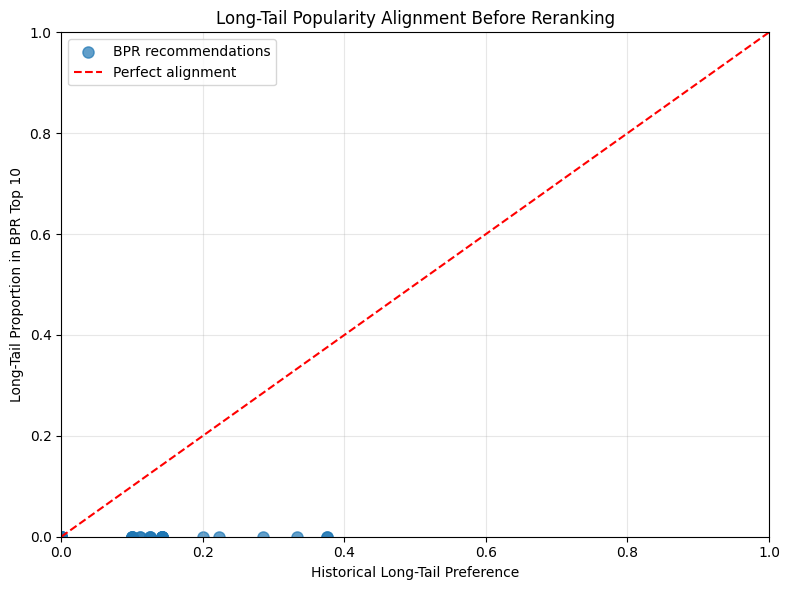

In [29]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

plt.scatter(
    bpr_pop_comparison['long_tail_preference'],
    bpr_pop_comparison['recommended_long_tail'],
    alpha=0.7,
    s=65,
    label='BPR recommendations'
)

# Perfect alignment reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='red',
    label='Perfect alignment'
)

plt.xlabel('Historical Long-Tail Preference')
plt.ylabel('Long-Tail Proportion in BPR Top 10')
plt.title('Long-Tail Popularity Alignment Before Reranking')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5 Measuring Popularity Calibration Error Before Reranking

To quantify the difference between users' historical popularity preferences and their BPR recommendation distributions, we calculate Total Variation Distance (TVD).

TVD measures the difference between two probability distributions across the long-tail, mid-tail, and popular activity groups. A value of 0 indicates perfect alignment, while a value of 1 indicates maximum disagreement.

We calculate TVD for each user and then examine the average calibration error across all 50 users. This establishes a numerical baseline for evaluating whether popularity-aware reranking improves the alignment between recommendations and users' historical preferences.

In [30]:
import numpy as np

# Historical popularity distributions
historical = bpr_pop_comparison[
    ['long_tail_preference',
     'mid_tail_preference',
     'popular_preference']
].to_numpy()

# BPR recommendation popularity distributions
recommended = bpr_pop_comparison[
    ['recommended_long_tail',
     'recommended_mid_tail',
     'recommended_popular']
].to_numpy()

# Calculate Total Variation Distance for each user
bpr_pop_comparison['calibration_error'] = (
    0.5 * np.abs(historical - recommended).sum(axis=1)
)

print("Average BPR calibration error:",
      round(bpr_pop_comparison['calibration_error'].mean(), 4))

print("Median BPR calibration error:",
      round(bpr_pop_comparison['calibration_error'].median(), 4))

print("Minimum calibration error:",
      round(bpr_pop_comparison['calibration_error'].min(), 4))

print("Maximum calibration error:",
      round(bpr_pop_comparison['calibration_error'].max(), 4))

Average BPR calibration error: 0.4129
Median BPR calibration error: 0.4365
Minimum calibration error: 0.0
Maximum calibration error: 0.8


### 3.6 Examining Popularity Group Availability in BPR Candidates

Before implementing popularity-aware reranking, we examine the availability of long-tail, mid-tail, and popular activities within each user's candidate pool.

Since reranking only changes the order of existing candidates, its ability to improve popularity alignment depends on whether the candidate pool contains activities from the user's preferred popularity groups.

We calculate the number of candidates belonging to each popularity group for every user and summarize their availability across the dataset. This helps identify potential limitations of popularity calibration before implementing the reranking algorithm.

In [32]:
# Count candidate activities in each popularity group per user
candidate_group_counts = pd.crosstab(
    reranking_data['user_id'],
    reranking_data['popularity_group']
).reindex(
    columns=['Long-tail', 'Mid-tail', 'Popular'],
    fill_value=0
)

print("Candidate availability across users:")
display(candidate_group_counts.describe().round(2))

print("\nUsers with zero long-tail candidates:",
      (candidate_group_counts['Long-tail'] == 0).sum())

print("Users with zero mid-tail candidates:",
      (candidate_group_counts['Mid-tail'] == 0).sum())

print("\nAverage candidates per user:",
      candidate_group_counts.sum(axis=1).mean())

Candidate availability across users:


popularity_group,Long-tail,Mid-tail,Popular
count,50.00,50.00,50.00
mean,0.50,60.00,139.50
std,3.26,44.39,45.64
min,0.00,0.00,18.00
25%,0.00,24.50,110.25
50%,0.00,51.00,149.00
75%,0.00,89.75,175.50
max,23.00,168.00,200.00



Users with zero long-tail candidates: 48
Users with zero mid-tail candidates: 1

Average candidates per user: 200.0


### 3.7 Measuring Candidate-Constrained Calibration Limits

The candidate availability analysis revealed that most users have no long-tail activities in their BPR candidate pools. This limits the ability of popularity-aware reranking to reproduce their historical popularity distributions.

To quantify this limitation, we calculate the minimum achievable Total Variation Distance for each user, assuming a top-10 recommendation list selected from their available candidates.

This provides a theoretical calibration benchmark that accounts for candidate availability and the discrete proportions possible in a top-10 list. Comparing this benchmark with the original BPR calibration error will help determine how much improvement is possible through reranking alone.

In [33]:
from itertools import product
import numpy as np

K = 10

# All possible popularity group counts in a top-K list
possible_counts = np.array([
    [long_tail, mid_tail, K - long_tail - mid_tail]
    for long_tail in range(K + 1)
    for mid_tail in range(K - long_tail + 1)
])

results = []

for _, user in bpr_pop_comparison.iterrows():

    user_id = user['user_id']

    # Historical popularity distribution
    target = np.array([
        user['long_tail_preference'],
        user['mid_tail_preference'],
        user['popular_preference']
    ])

    # Available candidate counts
    available = candidate_group_counts.loc[
        user_id, ['Long-tail', 'Mid-tail', 'Popular']
    ].to_numpy()

    # Only consider distributions possible with available candidates
    feasible = possible_counts[
        (possible_counts <= available).all(axis=1)
    ]

    if len(feasible) == 0:
        raise ValueError(f"Fewer than {K} candidates for user {user_id}")

    # Calculate TVD for every feasible top-10 distribution
    errors = 0.5 * np.abs(
        feasible / K - target
    ).sum(axis=1)

    minimum_error = errors.min()

    results.append({
        'user_id': user_id,
        'minimum_possible_error': minimum_error,
        'bpr_calibration_error': user['calibration_error']
    })

calibration_limits = pd.DataFrame(results)

print("Average minimum achievable error:",
      round(calibration_limits['minimum_possible_error'].mean(), 4))

print("Average original BPR error:",
      round(calibration_limits['bpr_calibration_error'].mean(), 4))

print("Average potential improvement:",
      round((
          calibration_limits['bpr_calibration_error']
          - calibration_limits['minimum_possible_error']
      ).mean(), 4))

Average minimum achievable error: 0.0978
Average original BPR error: 0.4129
Average potential improvement: 0.3151


### 3.8 Implementing Distribution-Aware Popularity Reranking

We implement a greedy popularity-aware reranking algorithm that balances predicted activity relevance with alignment to each user's historical popularity preferences.

The algorithm constructs a top-10 recommendation list by iteratively selecting candidates according to their normalized BPR scores and the effect of each selection on the list's popularity distribution.

A tunable parameter, lambda, controls the relative importance of relevance and popularity calibration. A value of 0 prioritizes BPR relevance, while larger values increase the influence of popularity alignment.

The algorithm operates only on activities available in each user's candidate pool. Its performance will be evaluated across multiple lambda values to identify the trade-off between relevance preservation and calibration improvement.

In [34]:
import numpy as np

POPULARITY_GROUPS = ['Long-tail', 'Mid-tail', 'Popular']

def popularity_rerank(user_candidates, lambda_weight=0.3, k=10):

    candidates = user_candidates.copy()

    # Historical popularity preferences
    target = candidates[
        ['long_tail_preference',
         'mid_tail_preference',
         'popular_preference']
    ].iloc[0].to_numpy(dtype=float)

    selected_indices = []
    selected_counts = np.zeros(3, dtype=int)

    for position in range(k):

        best_index = None
        best_score = -np.inf

        for idx, candidate in candidates.iterrows():

            if idx in selected_indices:
                continue

            group_index = POPULARITY_GROUPS.index(
                candidate['popularity_group']
            )

            # Popularity distribution after adding this candidate
            new_counts = selected_counts.copy()
            new_counts[group_index] += 1

            new_distribution = new_counts / (position + 1)

            # Calibration error
            calibration_error = 0.5 * np.abs(
                target - new_distribution
            ).sum()

            # Combined relevance-calibration objective
            relevance = candidate['bpr_normalized']

            combined_score = (
                (1 - lambda_weight) * relevance
                - lambda_weight * calibration_error
            )

            if combined_score > best_score:
                best_score = combined_score
                best_index = idx

        if best_index is None:
            break

        selected_indices.append(best_index)

        chosen_group = candidates.loc[
            best_index, 'popularity_group'
        ]

        selected_counts[
            POPULARITY_GROUPS.index(chosen_group)
        ] += 1

    reranked = candidates.loc[selected_indices].copy()
    reranked['reranked_rank'] = range(1, len(reranked) + 1)

    return reranked

### 3.9 Testing Popularity-Aware Reranking on a Single User

To examine the behavior of the popularity-aware reranking algorithm, we test it on a single user using different lambda values.

Lambda controls the balance between BPR relevance and popularity calibration. We compare the resulting top-10 recommendation distributions against the user's historical popularity preferences.

For each lambda value, we calculate the Total Variation Distance (TVD) and the proportion of original BPR top-10 activities retained after reranking.

This preliminary experiment helps determine whether increasing the influence of popularity calibration improves alignment while preserving relevant recommendations.

In [35]:
# Select a user with a substantial mid-tail preference
test_user_id = (
    bpr_pop_comparison
    .sort_values('mid_tail_preference', ascending=False)
    .iloc[0]['user_id']
)

user_candidates = reranking_data[
    reranking_data['user_id'] == test_user_id
].copy()

# Original BPR top 10
original_top10 = (
    user_candidates
    .sort_values('bpr_rank')
    .head(10)
)

original_ids = set(original_top10['gmap_id'])

target = user_candidates[
    ['long_tail_preference',
     'mid_tail_preference',
     'popular_preference']
].iloc[0].to_numpy(dtype=float)

lambda_values = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]

test_results = []

for lam in lambda_values:

    reranked = popularity_rerank(
        user_candidates,
        lambda_weight=lam,
        k=10
    )

    # Calculate reranked popularity distribution
    counts = reranked['popularity_group'].value_counts()

    distribution = np.array([
        counts.get(group, 0) / len(reranked)
        for group in POPULARITY_GROUPS
    ])

    # Total Variation Distance
    calibration_error = 0.5 * np.abs(
        target - distribution
    ).sum()

    # Original BPR top-10 preservation
    overlap = len(
        original_ids.intersection(set(reranked['gmap_id']))
    ) / 10

    test_results.append({
        'lambda': lam,
        'calibration_error': calibration_error,
        'top10_overlap': overlap,
        'long_tail': distribution[0],
        'mid_tail': distribution[1],
        'popular': distribution[2]
    })

single_user_results = pd.DataFrame(test_results)

print("Test user:", test_user_id)

print("\nHistorical popularity preferences:")
print(dict(zip(POPULARITY_GROUPS, target.round(3))))

print("\nReranking results:")
display(single_user_results.round(4))

Test user: 104539594252117689042

Historical popularity preferences:
{'Long-tail': 0.0, 'Mid-tail': 0.778, 'Popular': 0.222}

Reranking results:


,lambda,calibration_error,top10_overlap,long_tail,mid_tail,popular
0,0.0,0.5778,1.0,0.0,0.2,0.8
1,0.1,0.4778,0.9,0.0,0.3,0.7
2,0.2,0.4778,0.9,0.0,0.3,0.7
3,0.3,0.4778,0.9,0.0,0.3,0.7
4,0.5,0.4778,0.9,0.0,0.3,0.7
5,0.7,0.2778,0.7,0.0,0.5,0.5
6,1.0,0.0222,0.4,0.0,0.8,0.2


### 3.10 Visualizing the Relevance–Calibration Trade-Off

To examine the effect of the popularity calibration weight, we visualize how calibration error and BPR top-10 recommendation overlap change across different lambda values for the selected user.

The line graph illustrates the trade-off between aligning recommendations with historical popularity preferences and preserving the original BPR recommendations.

Lower calibration error indicates better popularity alignment, while higher top-10 overlap indicates greater preservation of the original recommendation set. This preliminary analysis helps identify how the reranking weight influences recommendation behavior before evaluating the algorithm across all users.

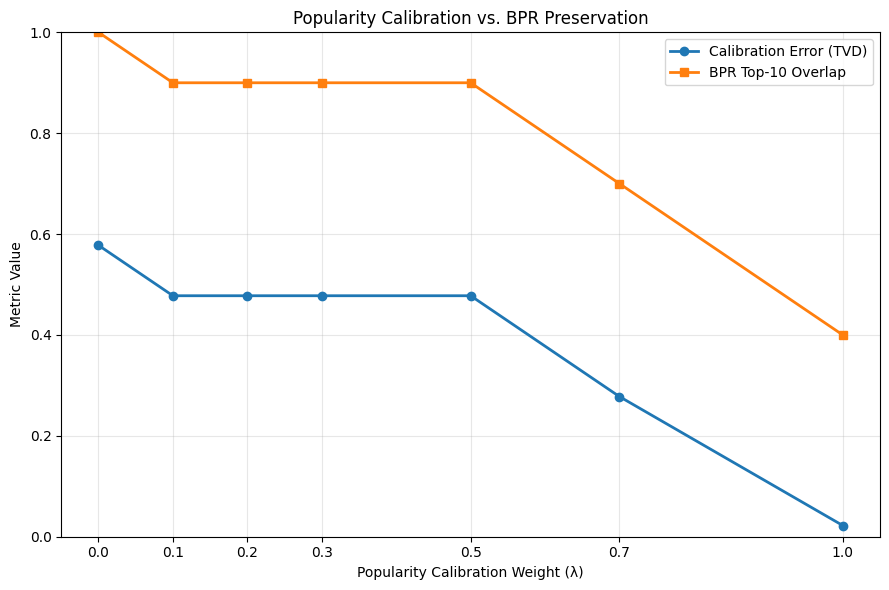

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    single_user_results['lambda'],
    single_user_results['calibration_error'],
    marker='o',
    linewidth=2,
    label='Calibration Error (TVD)'
)

plt.plot(
    single_user_results['lambda'],
    single_user_results['top10_overlap'],
    marker='s',
    linewidth=2,
    label='BPR Top-10 Overlap'
)

plt.xlabel('Popularity Calibration Weight (λ)')
plt.ylabel('Metric Value')
plt.title('Popularity Calibration vs. BPR Preservation')

plt.xticks(single_user_results['lambda'])
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.11 Evaluating Popularity-Aware Reranking Across All Users

We evaluate the popularity-aware reranking algorithm across all 50 users using different lambda values.

For each user and lambda value, we generate a reranked top-10 recommendation list and calculate its popularity calibration error using Total Variation Distance (TVD). We also measure the proportion of original BPR top-10 activities retained after reranking.

The results are aggregated across users to examine the overall relationship between popularity calibration and recommendation preservation.

This experiment provides a more representative assessment of the reranking algorithm and helps identify suitable lambda values for further evaluation.

In [37]:
lambda_values = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]

all_user_results = []

for user_id, user_candidates in reranking_data.groupby('user_id'):

    original_top10 = (
        user_candidates.sort_values('bpr_rank').head(10)
    )
    original_ids = set(original_top10['gmap_id'])

    target = user_candidates[
        ['long_tail_preference',
         'mid_tail_preference',
         'popular_preference']
    ].iloc[0].to_numpy(dtype=float)

    for lam in lambda_values:

        reranked = popularity_rerank(
            user_candidates,
            lambda_weight=lam,
            k=10
        )

        counts = reranked['popularity_group'].value_counts()

        distribution = np.array([
            counts.get(group, 0) / len(reranked)
            for group in POPULARITY_GROUPS
        ])

        calibration_error = (
            0.5 * np.abs(target - distribution).sum()
        )

        overlap = len(
            original_ids.intersection(set(reranked['gmap_id']))
        ) / 10

        all_user_results.append({
            'user_id': user_id,
            'lambda': lam,
            'calibration_error': calibration_error,
            'top10_overlap': overlap
        })

all_user_results = pd.DataFrame(all_user_results)

average_results = (
    all_user_results
    .groupby('lambda', as_index=False)
    .agg(
        avg_calibration_error=('calibration_error', 'mean'),
        avg_top10_overlap=('top10_overlap', 'mean')
    )
)

display(average_results.round(4))

print(
    "\nOriginal BPR average calibration error:",
    round(bpr_pop_comparison['calibration_error'].mean(), 4)
)

print(
    "Theoretical minimum average calibration error:",
    round(calibration_limits['minimum_possible_error'].mean(), 4)
)

,lambda,avg_calibration_error,avg_top10_overlap
0,0.0,0.4129,1.000
1,0.1,0.4089,0.996
2,0.2,0.4049,0.992
3,0.3,0.3934,0.980
4,0.5,0.3588,0.944
5,0.7,0.2624,0.846
6,1.0,0.0978,0.654



Original BPR average calibration error: 0.4129
Theoretical minimum average calibration error: 0.0978


### 3.12 Visualizing the Aggregate Calibration–Preservation Trade-Off

We visualize the average popularity calibration error and BPR top-10 recommendation overlap across all 50 users for different lambda values.

The graph illustrates how increasing the calibration weight affects the balance between historical popularity alignment and preservation of the original BPR recommendations.

We also include the theoretical minimum achievable calibration error as a reference. This benchmark represents the best possible popularity alignment under the available candidate pools and top-10 recommendation constraint.

The visualization helps identify promising reranking configurations for subsequent relevance and contextual suitability evaluation.

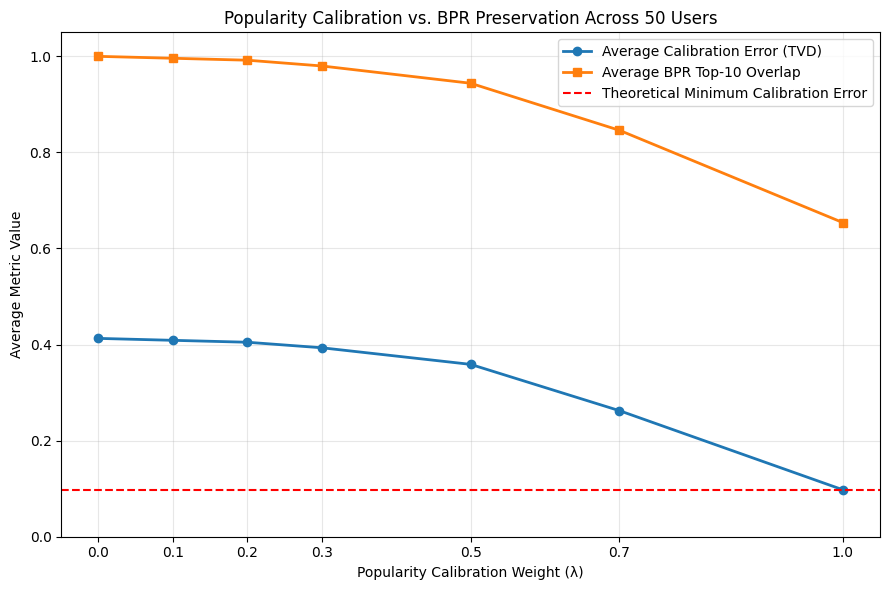

In [39]:
import matplotlib.pyplot as plt

theoretical_minimum = (
    calibration_limits['minimum_possible_error'].mean()
)

plt.figure(figsize=(9, 6))

plt.plot(
    average_results['lambda'],
    average_results['avg_calibration_error'],
    marker='o',
    linewidth=2,
    label='Average Calibration Error (TVD)'
)

plt.plot(
    average_results['lambda'],
    average_results['avg_top10_overlap'],
    marker='s',
    linewidth=2,
    label='Average BPR Top-10 Overlap'
)

plt.axhline(
    y=theoretical_minimum,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Theoretical Minimum Calibration Error'
)

plt.xlabel('Popularity Calibration Weight (λ)')
plt.ylabel('Average Metric Value')
plt.title('Popularity Calibration vs. BPR Preservation Across 50 Users')

plt.xticks(average_results['lambda'])
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.13 Evaluating BPR Relevance Preservation

To assess the effect of popularity-aware reranking on predicted recommendation relevance, we compare the average normalized BPR scores of the original and reranked top-10 recommendation lists.

For each user and lambda value, we calculate the mean normalized BPR score of the selected activities. We then aggregate these values across all 50 users and measure the relative change from the original BPR baseline.

This analysis complements the top-10 overlap metric by measuring changes in predicted relevance rather than simply counting how many original recommendations are retained.

Although normalized BPR scores provide a useful model-based relevance indicator, they do not replace evaluation against held-out user interactions using metrics such as NDCG@10 or Recall@10.

In [40]:
relevance_results = []

for user_id, user_candidates in reranking_data.groupby('user_id'):

    original_top10 = (
        user_candidates
        .sort_values('bpr_rank')
        .head(10)
    )

    original_relevance = original_top10['bpr_normalized'].mean()

    for lam in lambda_values:

        reranked = popularity_rerank(
            user_candidates,
            lambda_weight=lam,
            k=10
        )

        reranked_relevance = reranked['bpr_normalized'].mean()

        relevance_results.append({
            'user_id': user_id,
            'lambda': lam,
            'original_relevance': original_relevance,
            'reranked_relevance': reranked_relevance,
            'relative_relevance_change': (
                (reranked_relevance - original_relevance)
                / original_relevance
                if original_relevance != 0 else np.nan
            )
        })

relevance_results = pd.DataFrame(relevance_results)

average_relevance_results = (
    relevance_results
    .groupby('lambda', as_index=False)
    .agg(
        avg_bpr_relevance=('reranked_relevance', 'mean'),
        avg_relative_change=('relative_relevance_change', 'mean')
    )
)

average_relevance_results['avg_relative_change_pct'] = (
    average_relevance_results['avg_relative_change'] * 100
)

display(
    average_relevance_results[
        ['lambda', 'avg_bpr_relevance', 'avg_relative_change_pct']
    ].round(4)
)

,lambda,avg_bpr_relevance,avg_relative_change_pct
0,0.0,0.7617,0.0000
1,0.1,0.7617,-0.0031
2,0.2,0.7616,-0.0152
3,0.3,0.7612,-0.0679
4,0.5,0.7568,-0.6759
5,0.7,0.7307,-4.1585
6,1.0,0.6396,-15.7029


### 3.14 Visualizing the Calibration–Relevance Trade-Off

We examine the relationship between popularity calibration and predicted recommendation relevance across different reranking weights.

For each lambda value, we compare the average Total Variation Distance (TVD) with the average normalized BPR relevance score across all 50 users.

The resulting scatter plot illustrates the trade-off between improving popularity-distribution alignment and preserving predicted user preference. Each point represents a different lambda configuration.

This analysis helps identify promising reranking settings that achieve meaningful calibration improvements without excessive reductions in predicted relevance.

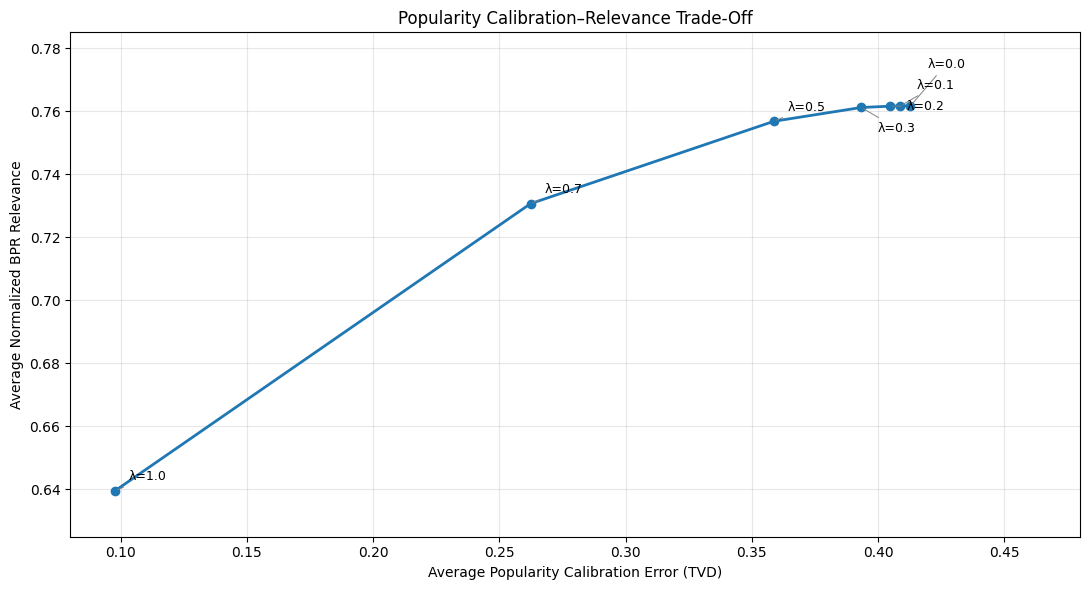

In [43]:
import matplotlib.pyplot as plt

tradeoff_results = average_results.merge(
    average_relevance_results,
    on='lambda',
    validate='one_to_one'
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    tradeoff_results['avg_calibration_error'],
    tradeoff_results['avg_bpr_relevance'],
    marker='o',
    linewidth=2
)

# Custom label positions to prevent overlapping
label_offsets = {
    0.0: (12, 30),
    0.1: (12, 15),
    0.2: (12, 0),
    0.3: (12, -15),
    0.5: (10, 10),
    0.7: (10, 10),
    1.0: (10, 10)
}

for _, row in tradeoff_results.iterrows():

    lam = round(row['lambda'], 1)

    ax.annotate(
        f"λ={lam:.1f}",
        (
            row['avg_calibration_error'],
            row['avg_bpr_relevance']
        ),
        xytext=label_offsets[lam],
        textcoords='offset points',
        fontsize=9,
        ha='left',
        va='center',
        arrowprops=dict(
            arrowstyle='-',
            color='gray',
            lw=0.7
        )
    )

ax.set_xlabel('Average Popularity Calibration Error (TVD)')
ax.set_ylabel('Average Normalized BPR Relevance')
ax.set_title('Popularity Calibration–Relevance Trade-Off')

# Add room for annotations
ax.set_xlim(0.08, 0.48)
ax.set_ylim(0.625, 0.785)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.15 Evaluating Ranking Order After Popularity Reranking

We examine how popularity-aware reranking affects the ordering of activities according to their predicted BPR relevance.

For each user and lambda value, we calculate the proportion of activity pairs in the reranked top-10 list whose ordering is inconsistent with their BPR scores. A pair is considered inverted when an activity with a lower BPR score is ranked above an activity with a higher BPR score.

We aggregate these inversion rates across all users to determine how strongly popularity calibration changes the relevance-based ranking order.

This analysis helps assess whether the current greedy reranking strategy requires further refinement before integration with contextual recommendation scores.

In [44]:
ranking_order_results = []

for user_id, user_candidates in reranking_data.groupby('user_id'):

    for lam in lambda_values:

        reranked = popularity_rerank(
            user_candidates,
            lambda_weight=lam,
            k=10
        )

        scores = reranked['bpr_normalized'].to_numpy()

        inversions = 0
        comparable_pairs = 0

        for i in range(len(scores)):
            for j in range(i + 1, len(scores)):

                # Ignore pairs with identical BPR scores
                if np.isclose(scores[i], scores[j]):
                    continue

                comparable_pairs += 1

                if scores[i] < scores[j]:
                    inversions += 1

        inversion_rate = (
            inversions / comparable_pairs
            if comparable_pairs > 0 else 0.0
        )

        ranking_order_results.append({
            'user_id': user_id,
            'lambda': lam,
            'inversion_rate': inversion_rate
        })

ranking_order_results = pd.DataFrame(ranking_order_results)

average_ranking_order = (
    ranking_order_results
    .groupby('lambda', as_index=False)
    .agg(
        avg_inversion_rate=('inversion_rate', 'mean')
    )
)

average_ranking_order['avg_inversion_pct'] = (
    average_ranking_order['avg_inversion_rate'] * 100
)

display(
    average_ranking_order[
        ['lambda', 'avg_inversion_pct']
    ].round(2)
)

,lambda,avg_inversion_pct
0,0.0,0.00
1,0.1,0.80
2,0.2,1.51
3,0.3,2.80
4,0.5,9.02
5,0.7,19.64
6,1.0,22.13


### 3.16 Comparing Candidate Reranking Configurations

We compare the original BPR recommendations against two promising popularity-aware reranking configurations, lambda = 0.5 and lambda = 0.7.

The comparison considers four metrics: popularity calibration error, normalized BPR relevance, top-10 recommendation overlap, and ranking inversion rate.

These metrics provide complementary perspectives on the trade-off between popularity alignment and preservation of predicted relevance.

The results will be used to identify a provisional reranking configuration for integration with the contextual recommendation system. Final parameter selection will require evaluation using held-out interactions and contextual suitability metrics.

In [45]:
# Combine all evaluation metrics
configuration_comparison = (
    average_results
    .merge(
        average_relevance_results[
            ['lambda', 'avg_bpr_relevance',
             'avg_relative_change_pct']
        ],
        on='lambda',
        validate='one_to_one'
    )
    .merge(
        average_ranking_order[
            ['lambda', 'avg_inversion_pct']
        ],
        on='lambda',
        validate='one_to_one'
    )
)

# Compare baseline and promising configurations
configuration_comparison = configuration_comparison[
    configuration_comparison['lambda'].isin([0.0, 0.5, 0.7])
].copy()

configuration_comparison['calibration_improvement_pct'] = (
    (0.4129 - configuration_comparison['avg_calibration_error'])
    / 0.4129 * 100
)

display(configuration_comparison.round(4))

,lambda,avg_calibration_error,avg_top10_overlap,avg_bpr_relevance,avg_relative_change_pct,avg_inversion_pct,calibration_improvement_pct
0,0.0,0.4129,1.000,0.7617,0.0000,0.0000,0.0104
4,0.5,0.3588,0.944,0.7568,-0.6759,9.0222,13.1059
5,0.7,0.2624,0.846,0.7307,-4.1585,19.6444,36.4599


### 3.17 Preparing Popularity-Aware Reranking for Contextual Integration

To support integration with the complete recommendation system, we extend the popularity-aware reranking function to accept a configurable relevance-score column.

This allows the algorithm to operate on either normalized BPR scores or context-adjusted relevance scores without changing its popularity calibration objective.

The revised function preserves the greedy distribution-aware selection strategy and introduces a configurable relevance input, enabling modular integration with contextual factors such as budget, weather, time, and distance.

The calibration weight remains adjustable so that different relevance–calibration trade-offs can be evaluated after integration.

In [47]:
def popularity_rerank_integrated(
    user_candidates,
    lambda_weight=0.7,
    k=10,
    relevance_column='bpr_normalized'
):
    if not 0 <= lambda_weight <= 1:
        raise ValueError("lambda_weight must be between 0 and 1")

    if relevance_column not in user_candidates.columns:
        raise ValueError(
            f"Missing relevance column: {relevance_column}"
        )

    candidates = user_candidates.copy()

    if len(candidates) < k:
        raise ValueError("Not enough candidates for requested k")

    target = candidates[
        ['long_tail_preference',
         'mid_tail_preference',
         'popular_preference']
    ].iloc[0].to_numpy(dtype=float)

    selected_indices = []
    selected_counts = np.zeros(3, dtype=int)

    for position in range(k):

        best_index = None
        best_score = -np.inf

        for idx, candidate in candidates.iterrows():

            if idx in selected_indices:
                continue

            group_index = POPULARITY_GROUPS.index(
                candidate['popularity_group']
            )

            new_counts = selected_counts.copy()
            new_counts[group_index] += 1

            new_distribution = new_counts / (position + 1)

            calibration_error = (
                0.5 * np.abs(target - new_distribution).sum()
            )

            relevance = float(candidate[relevance_column])

            combined_score = (
                (1 - lambda_weight) * relevance
                - lambda_weight * calibration_error
            )

            if combined_score > best_score:
                best_score = combined_score
                best_index = idx

        selected_indices.append(best_index)

        chosen_group = candidates.loc[
            best_index, 'popularity_group'
        ]

        selected_counts[
            POPULARITY_GROUPS.index(chosen_group)
        ] += 1

    reranked = candidates.loc[selected_indices].copy()
    reranked['reranked_rank'] = range(1, k + 1)

    return reranked

### 3.18 Verifying Reranker Compatibility

We validate the integration-ready popularity-aware reranking function by comparing its output with the original implementation.

Both functions are evaluated across all 50 users using the same BPR relevance scores and calibration weights of 0.5 and 0.7.

We compare the ordered recommendation lists to verify that introducing a configurable relevance-score column does not change the algorithm's behavior.

Identical outputs confirm that the updated implementation preserves the original reranking logic and is suitable for subsequent contextual integration.

In [48]:
compatibility_results = []

for user_id, user_candidates in reranking_data.groupby('user_id'):

    for lam in [0.5, 0.7]:

        original = popularity_rerank(
            user_candidates,
            lambda_weight=lam,
            k=10
        )

        integrated = popularity_rerank_integrated(
            user_candidates,
            lambda_weight=lam,
            k=10,
            relevance_column='bpr_normalized'
        )

        # Compare activity IDs in their ranked order
        identical = (
            original['gmap_id'].tolist()
            == integrated['gmap_id'].tolist()
        )

        compatibility_results.append({
            'user_id': user_id,
            'lambda': lam,
            'identical': identical
        })

compatibility_results = pd.DataFrame(compatibility_results)

print("Total comparisons:", len(compatibility_results))

print(
    "Identical rankings:",
    compatibility_results['identical'].sum()
)

print(
    "Mismatched rankings:",
    (~compatibility_results['identical']).sum()
)

print(
    "Compatibility rate:",
    f"{compatibility_results['identical'].mean() * 100:.1f}%"
)

Total comparisons: 100
Identical rankings: 100
Mismatched rankings: 0
Compatibility rate: 100.0%
